In [1]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import PartialDependenceDisplay

import shap
import lime
import lime.lime_tabular

import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

# **Import Data**

In [2]:
y = pd.read_csv('../data/y.csv')

y = np.array(y)
y_normalized = MinMaxScaler().fit_transform(y)
y_log = np.array(np.log(y)).reshape(-1, 1)
y_log_normalized = MinMaxScaler().fit_transform(y_log)

y = y.ravel()
y_normalized = y_normalized.ravel()
y_log = y_log.ravel()
y_log_normalized = y_log_normalized.ravel()

In [3]:
automatic_selected_features = pd.read_csv('../data/selected_features.csv').iloc[:, 0].tolist()

columns = pd.read_csv('../data/X.csv').columns
other_features = columns[columns.str.contains('PBA')].tolist()
other_features.extend(['SQFT', 'NFLOOR', 'CDD65', 'HDD65'])

X = pd.read_csv('../data/X.csv')
X_automatic = X[automatic_selected_features]
X_other = X[other_features]

# **Fit Selected Model**

In [4]:
random_forest_regressor_automatic = RandomForestRegressor(max_depth=8, n_estimators=120, n_jobs=-1, random_state=42)
random_forest_regressor_automatic.fit(X_automatic, y_normalized)

RandomForestRegressor(max_depth=8, n_estimators=120, n_jobs=-1, random_state=42)

In [5]:
random_forest_regressor_other = RandomForestRegressor(max_depth=6, n_estimators=120, n_jobs=-1, random_state=42)
random_forest_regressor_other.fit(X_other, y_normalized)

RandomForestRegressor(max_depth=6, n_estimators=120, n_jobs=-1, random_state=42)

# **Feature Importance**

In [6]:
df_importance_automatic = pd.DataFrame({
    "Variables": X_automatic.columns,
    "Importance": random_forest_regressor_automatic.feature_importances_
})

print(df_importance_automatic.sort_values("Importance", ascending = False).to_latex(index=False))   

\begin{tabular}{lr}
\toprule
Variables &  Importance \\
\midrule
     SQFT &    0.514234 \\
    HCBED &    0.118017 \\
   NELVTR &    0.067309 \\
    PKLTN &    0.062359 \\
    WKHRS &    0.059358 \\
    NWKER &    0.043055 \\
   RFGICN &    0.039979 \\
  SERVERN &    0.037094 \\
  SNACKSF &    0.033146 \\
    CAFSF &    0.025450 \\
\bottomrule
\end{tabular}



In [7]:
df_importance_other = pd.DataFrame({
    "Variables": X_other.columns,
    "Importance": random_forest_regressor_other.feature_importances_
})

print(df_importance_other.sort_values("Importance", ascending = False).to_latex(index=False))   

\begin{tabular}{lr}
\toprule
                   Variables &   Importance \\
\midrule
                        SQFT & 6.373908e-01 \\
     PBA\_INPATIENTHEALTHCARE & 1.621987e-01 \\
                       CDD65 & 6.890936e-02 \\
                       HDD65 & 4.420694e-02 \\
                      NFLOOR & 3.276191e-02 \\
                   PBA\_OTHER & 2.655358e-02 \\
              PBA\_LABORATORY & 1.150617e-02 \\
          PBA\_PUBLICASSEMBLY & 6.467703e-03 \\
                 PBA\_LODGING & 4.589358e-03 \\
PBA\_NONREFRIGERATEDWAREHOUSE & 3.196924e-03 \\
                  PBA\_OFFICE & 1.698990e-03 \\
               PBA\_FOODSALES & 1.457468e-04 \\
            PBA\_ENCLOSEDMALL & 9.814823e-05 \\
    PBA\_OUTPATIENTHEALTHCARE & 9.367112e-05 \\
               PBA\_EDUCATION & 7.828798e-05 \\
            PBA\_PUBLICSAFETY & 5.515075e-05 \\
   PBA\_REFRIGERATEDWAREHOUSE & 1.970313e-05 \\
             PBA\_FOODSERVICE & 1.472150e-05 \\
                 PBA\_NURSING & 4.503872e-06 \\
       

# **Model Agnostic**

## **Partial Dependence and ICE**

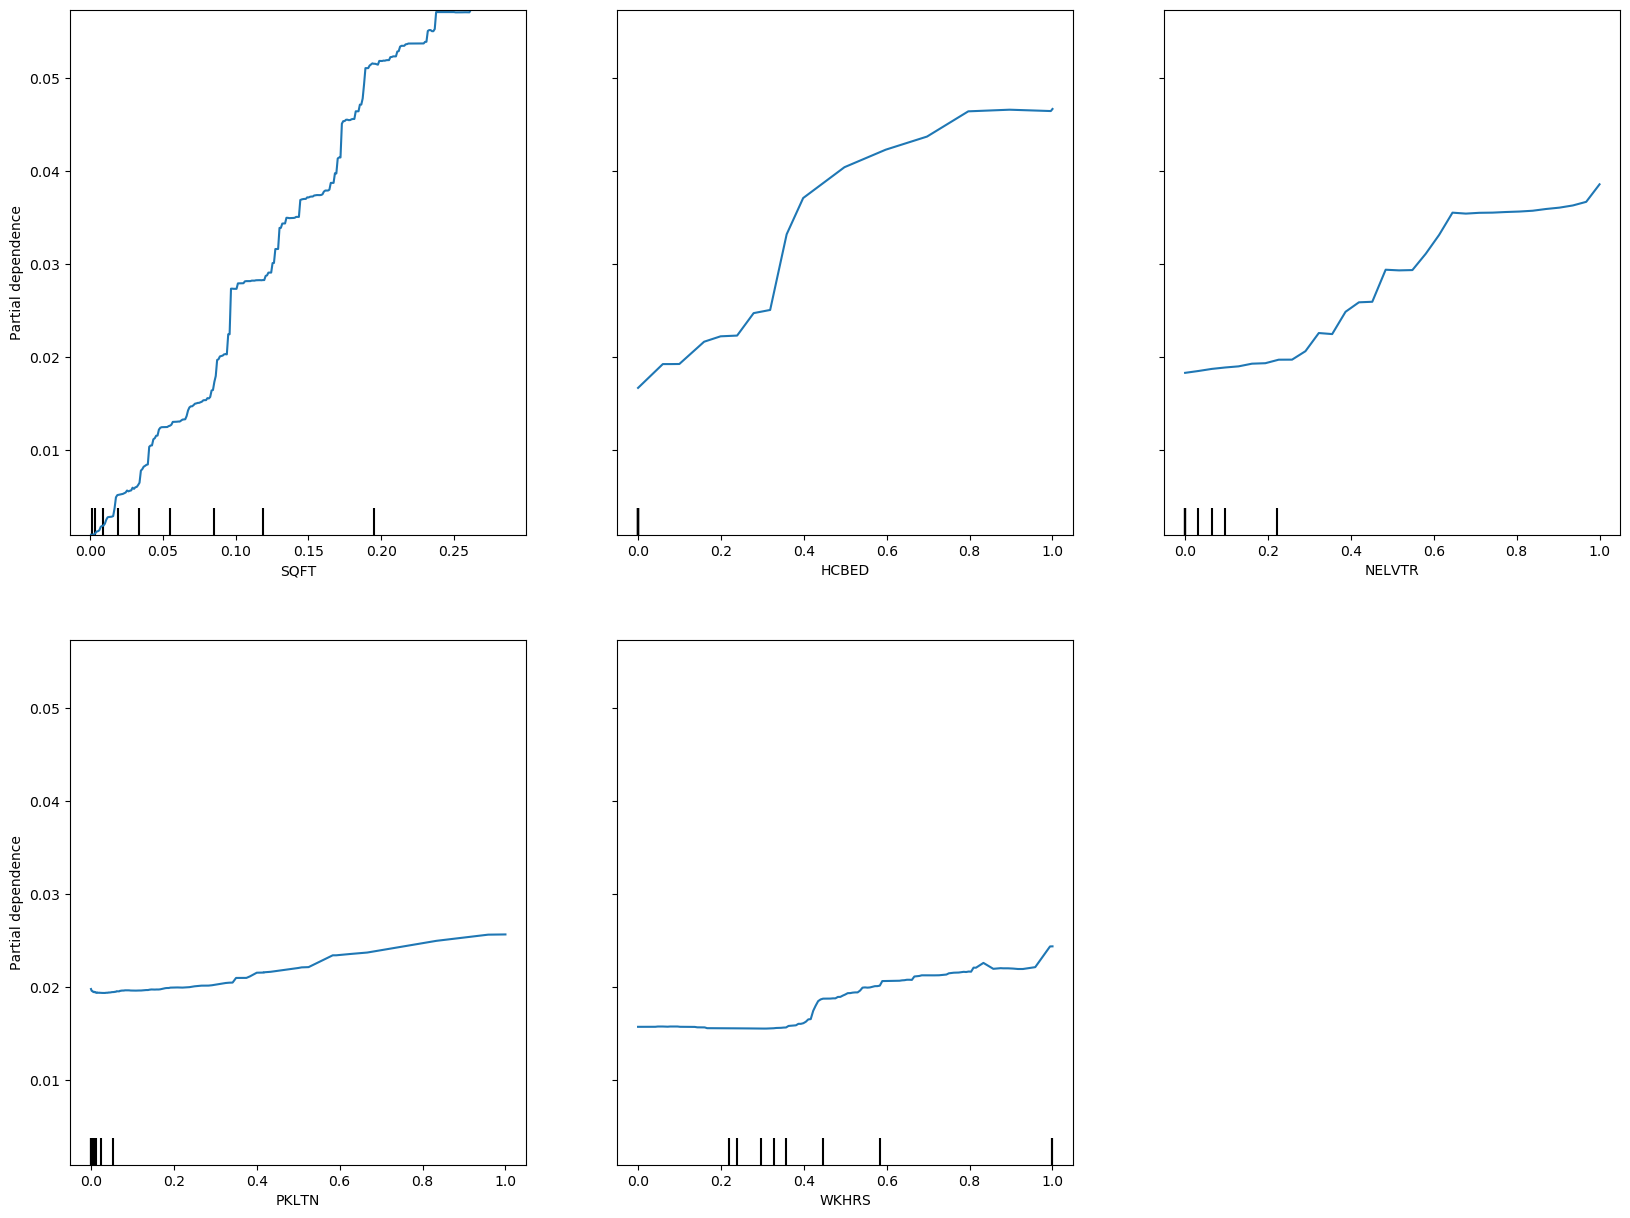

In [8]:
features = df_importance_automatic.sort_values("Importance", ascending = False).iloc[0:5,0].values.tolist()

feature_index = []
for name in features:
    i = X_automatic.columns.tolist().index(name)
    feature_index.append(i)
feature_index

pd_plot = PartialDependenceDisplay.from_estimator(random_forest_regressor_automatic, X_automatic, features = feature_index, feature_names= X_automatic.columns, grid_resolution = 300)
pd_plot.figure_.set_size_inches(20, 15)
plt.savefig('../images/partialdependenceplot_automaticfeatures.png', dpi=300)

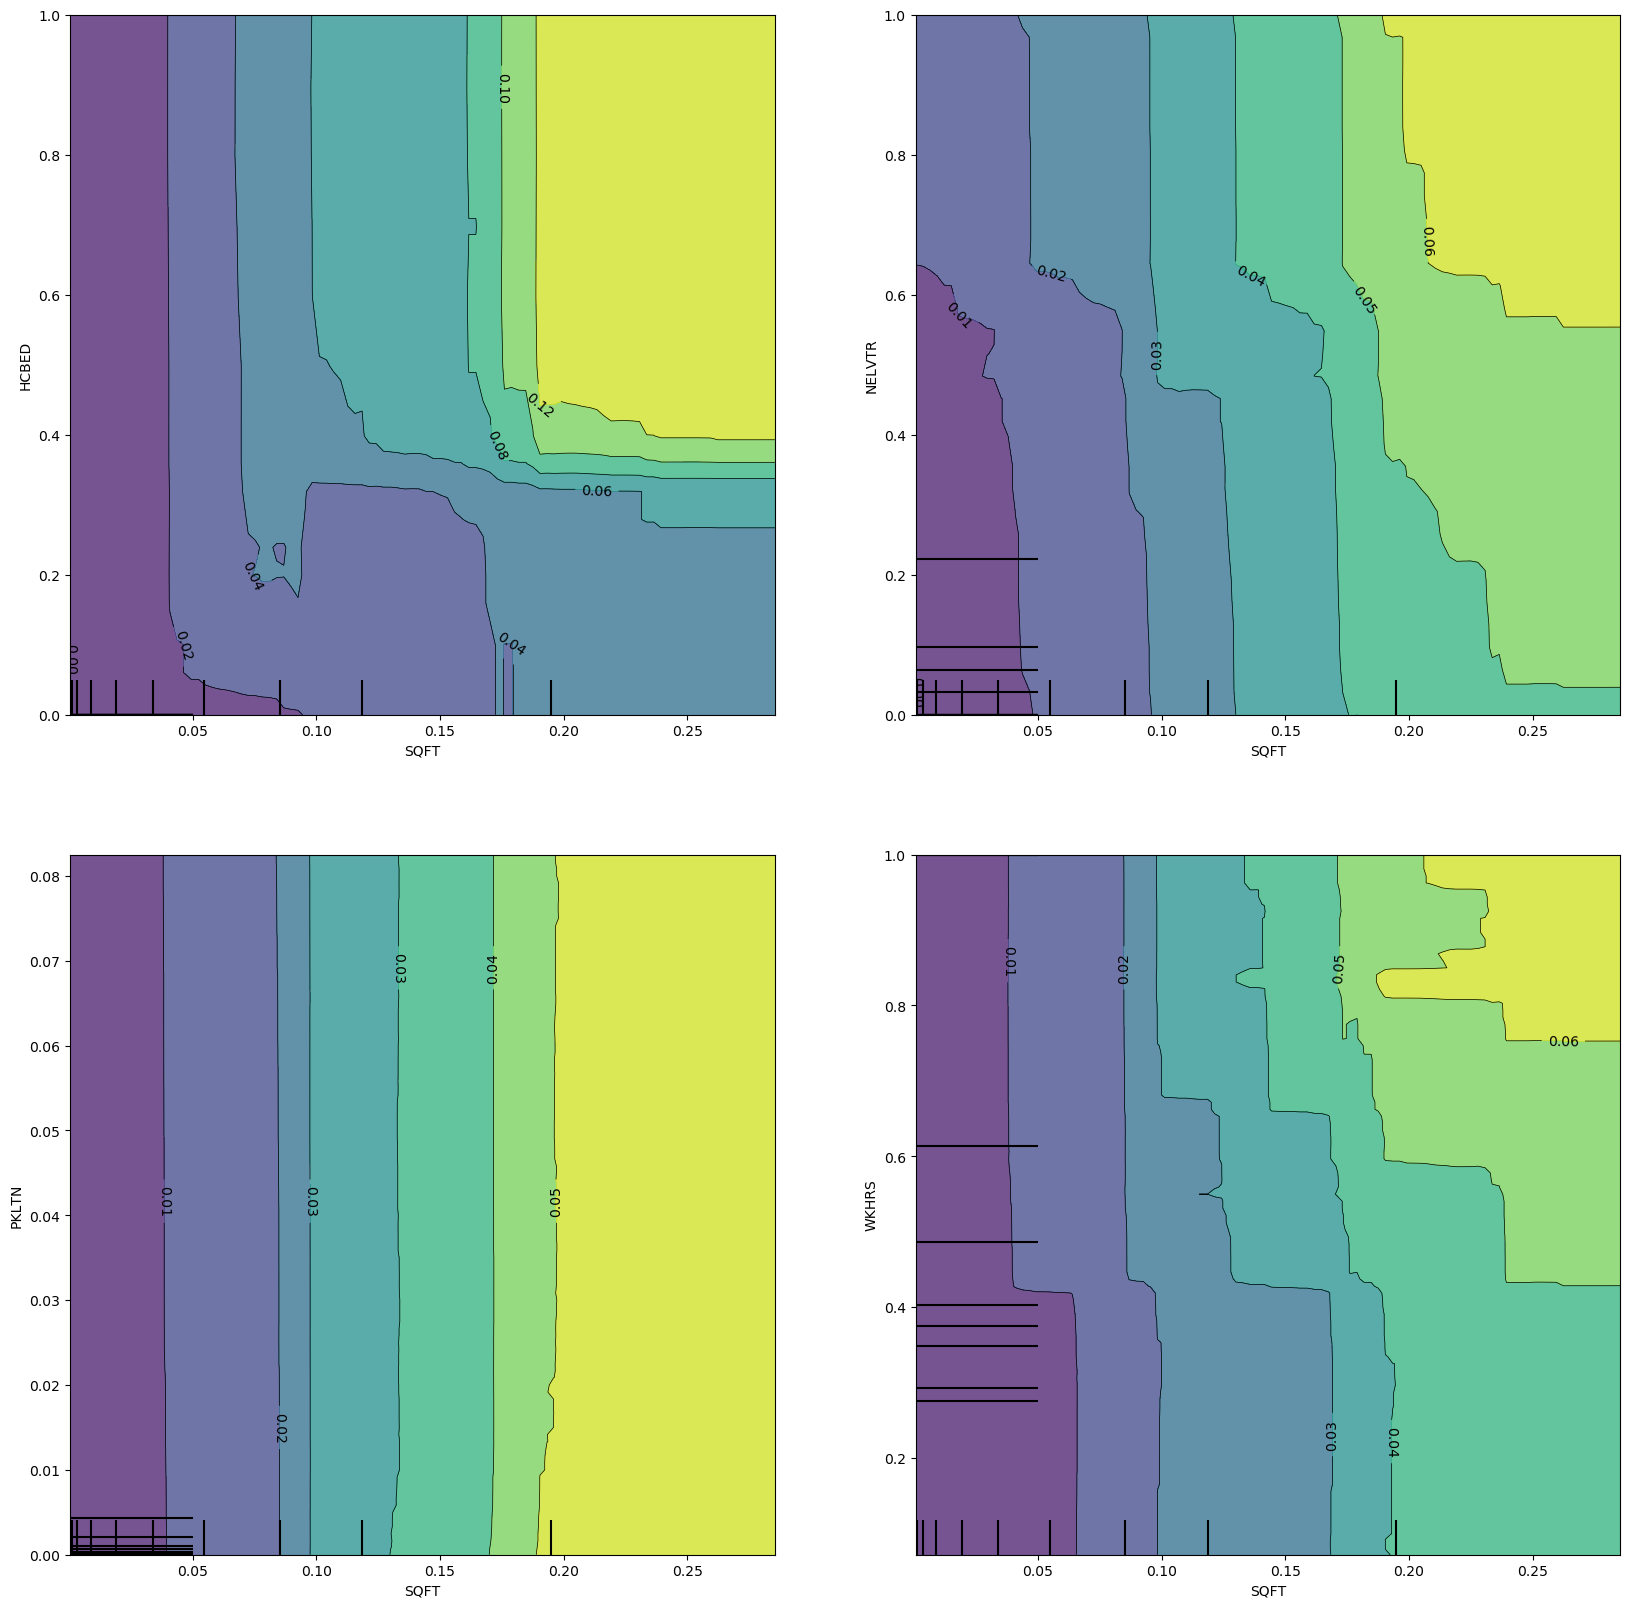

In [9]:
fix, axes = plt.subplots(2, 2, figsize=(20,20))
axes = axes.ravel()


for i, feature in enumerate(['HCBED', 'NELVTR', 'PKLTN', 'WKHRS']):
    
    index = [(X_automatic.columns.tolist().index('SQFT'), X_automatic.columns.tolist().index(feature))]
    pd_plot = PartialDependenceDisplay.from_estimator(random_forest_regressor_automatic, X_automatic, features = index, feature_names= X_automatic.columns, ax=axes[i])
    pd_plot.figure_.set_size_inches(20, 20)

plt.savefig('../images/partialdependence_automaticfeatures_sqft.png', dpi=300)

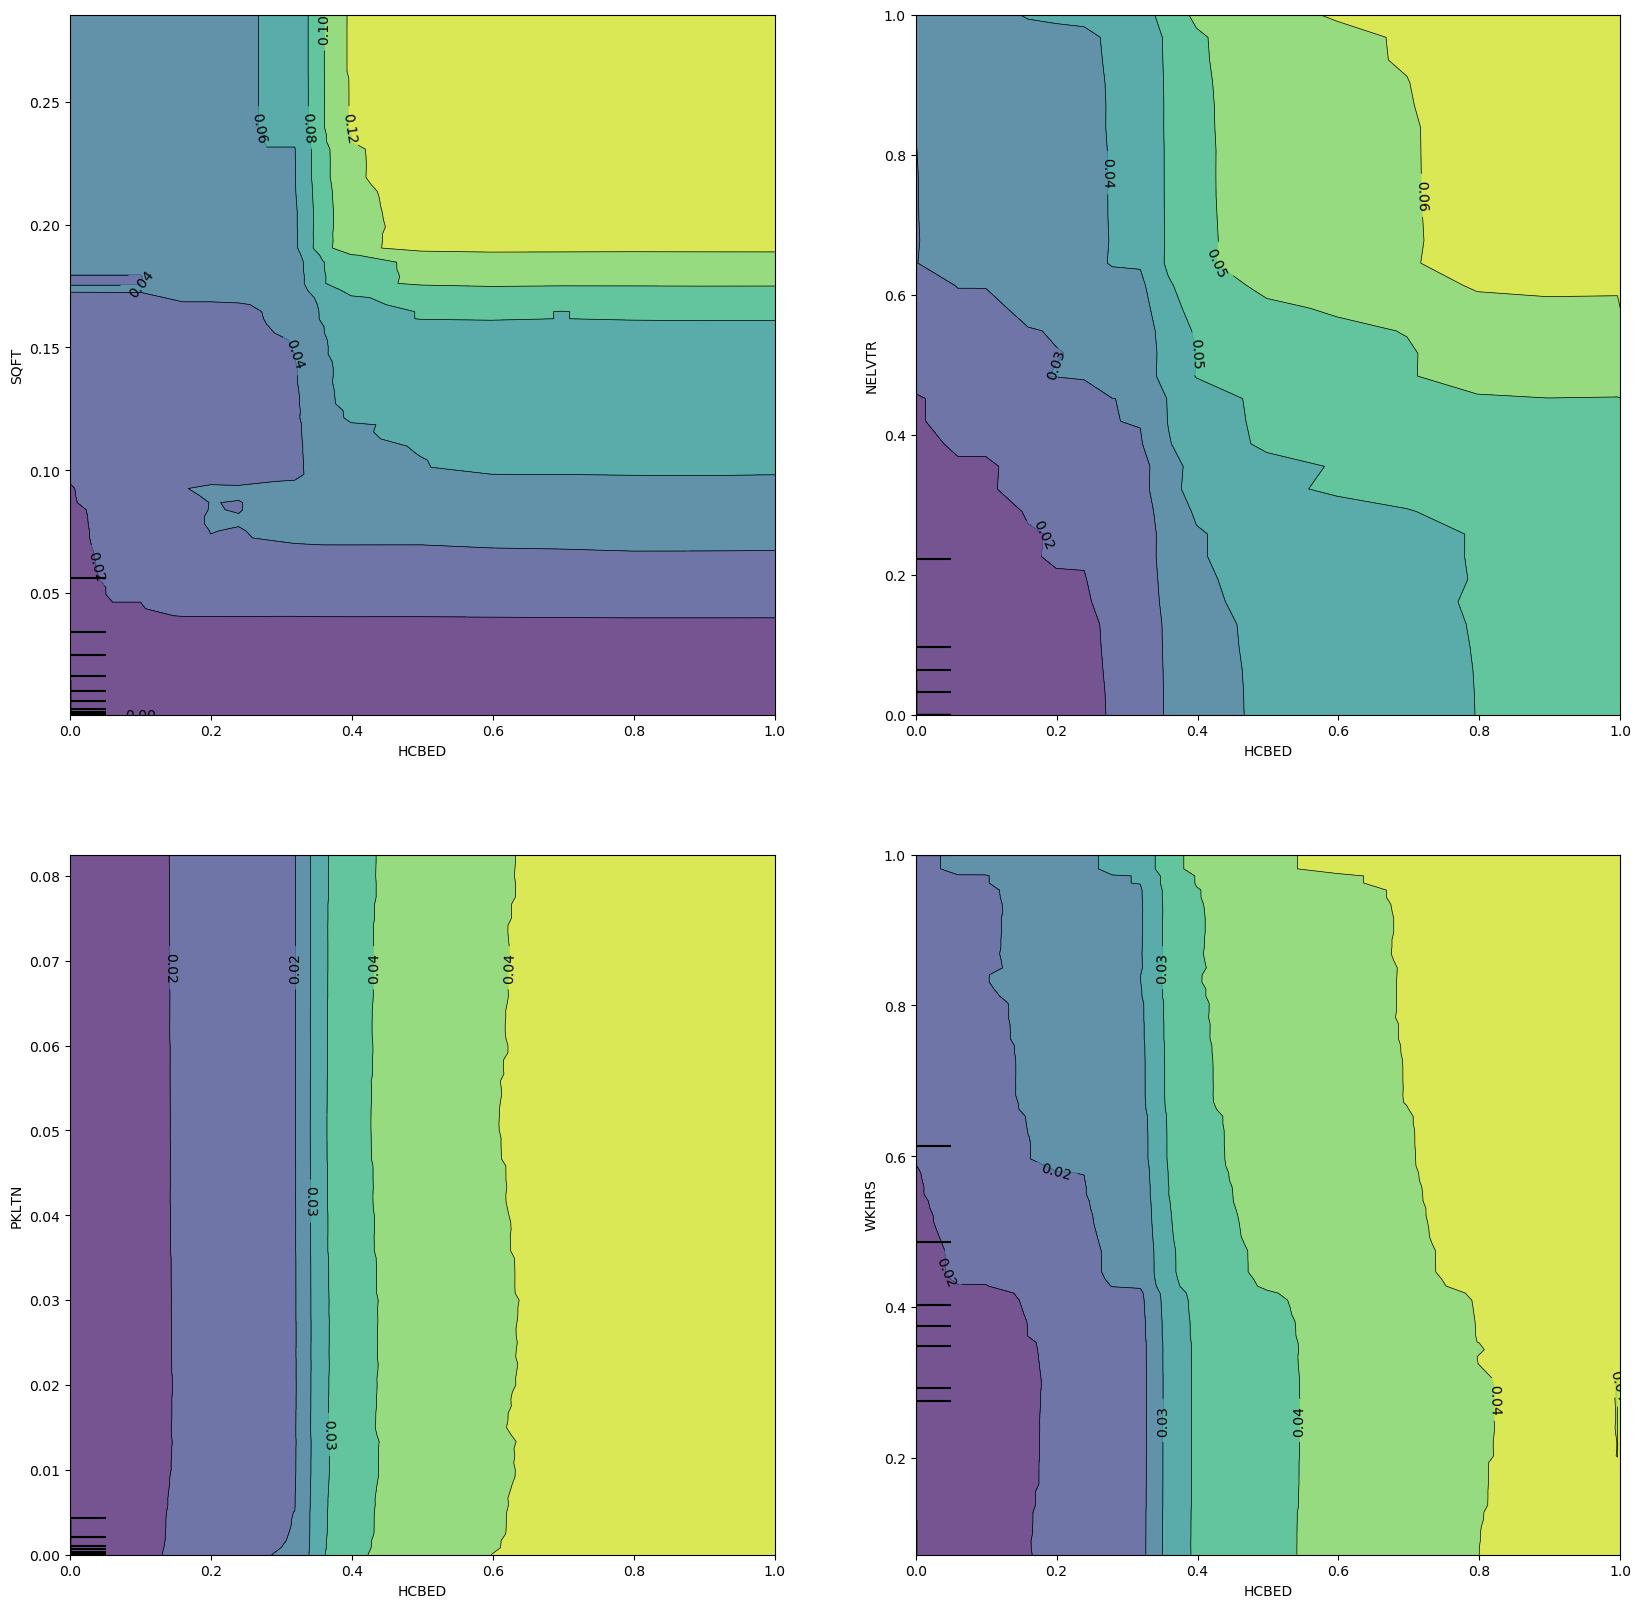

In [10]:
fix, axes = plt.subplots(2, 2, figsize=(20,20))
axes = axes.ravel()


for i, feature in enumerate(['SQFT', 'NELVTR', 'PKLTN', 'WKHRS']):
    
    index = [(X_automatic.columns.tolist().index('HCBED'), X_automatic.columns.tolist().index(feature))]
    pd_plot = PartialDependenceDisplay.from_estimator(random_forest_regressor_automatic, X_automatic, features = index, feature_names= X_automatic.columns, ax=axes[i])
    pd_plot.figure_.set_size_inches(20, 20)

plt.savefig('../images/partialdependence_automaticfeatures_hcbed.png', dpi=300)

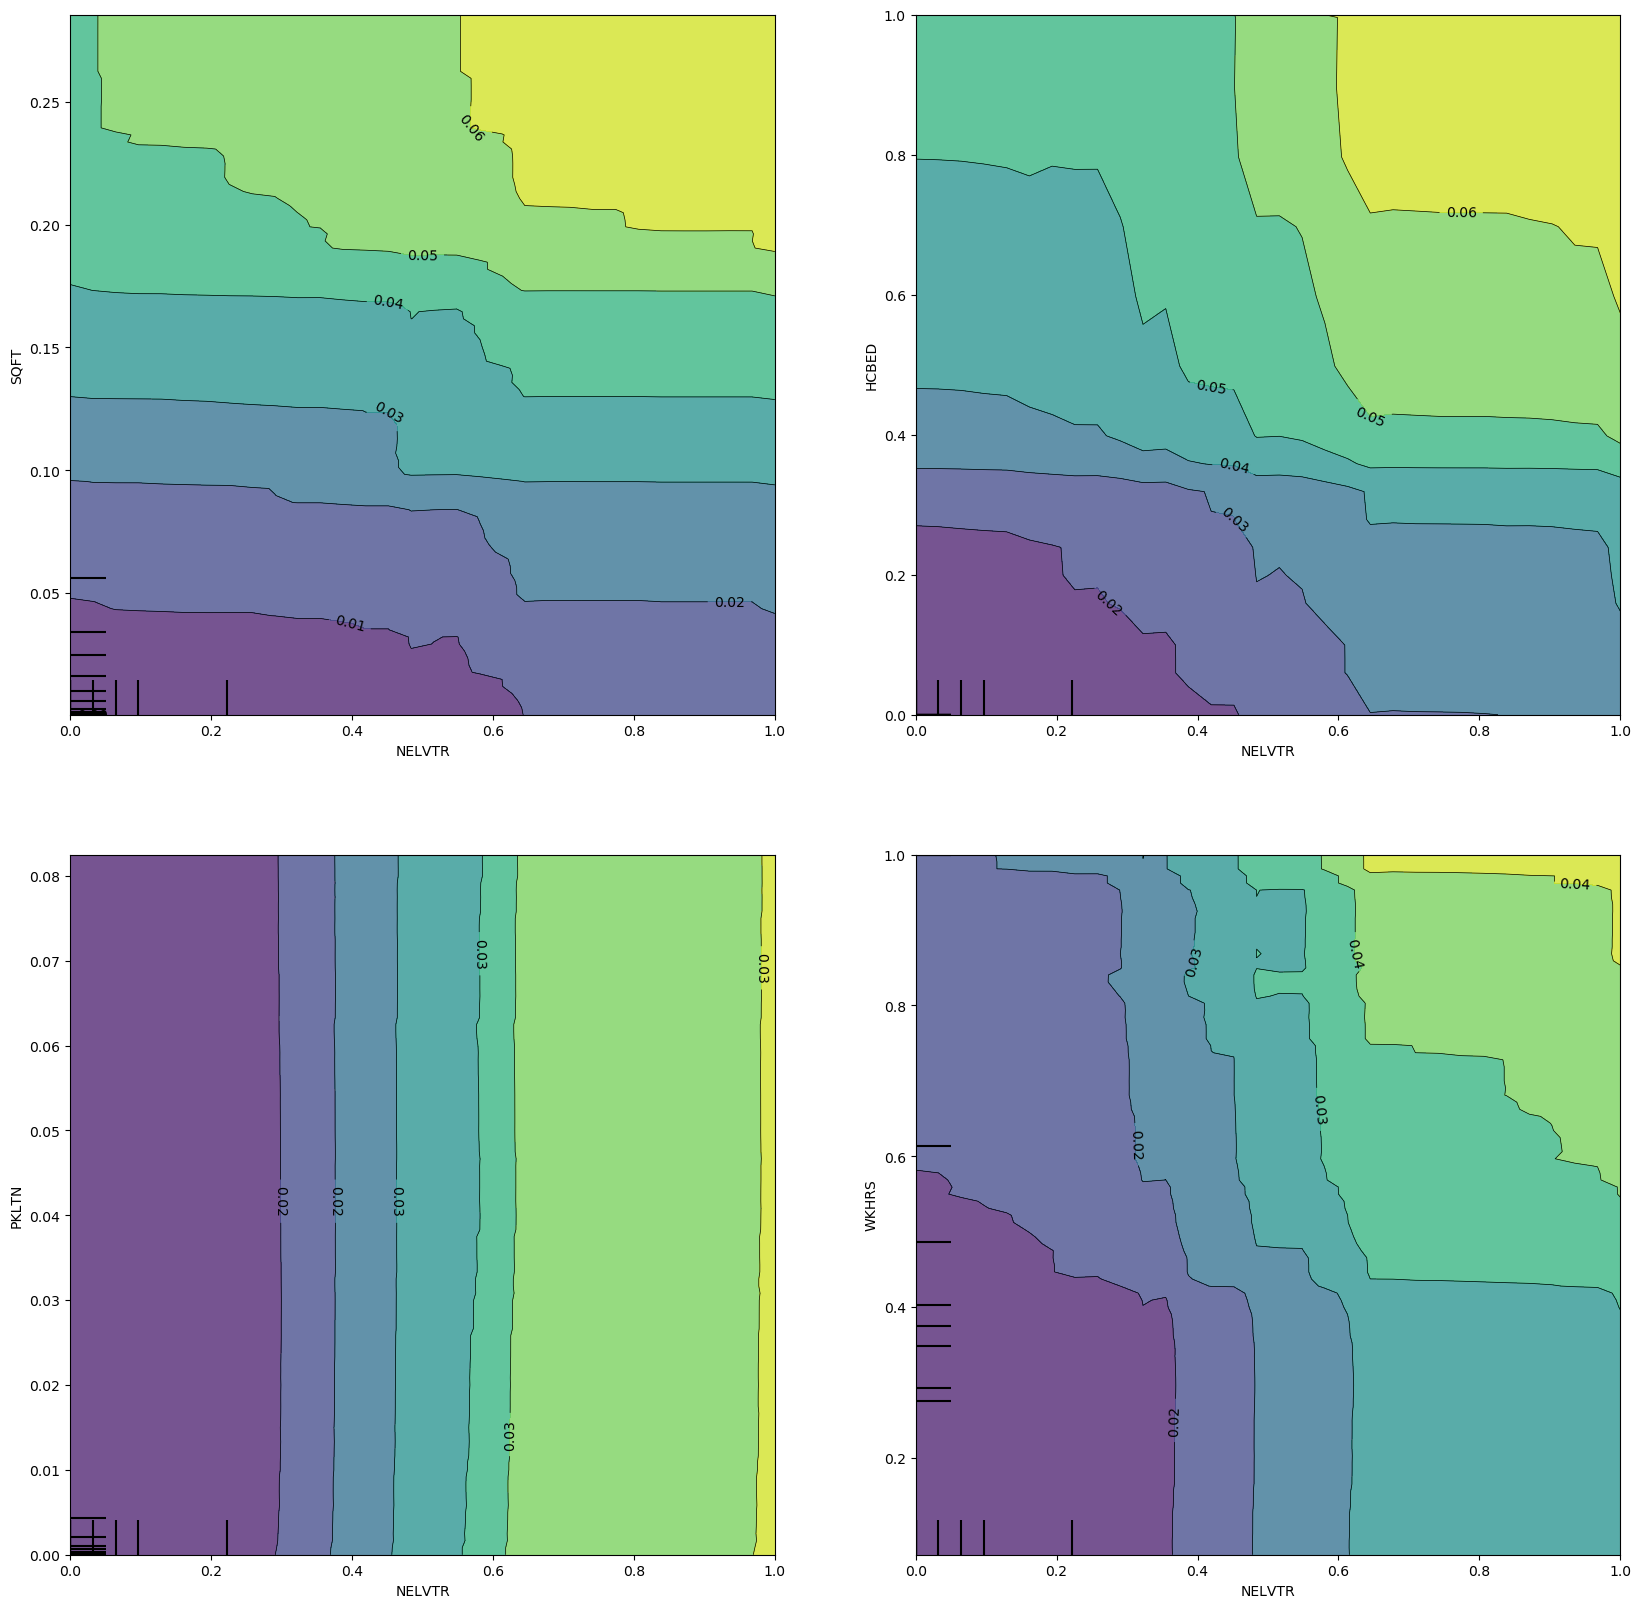

In [11]:
fix, axes = plt.subplots(2, 2, figsize=(20,20))
axes = axes.ravel()


for i, feature in enumerate(['SQFT', 'HCBED', 'PKLTN', 'WKHRS']):
    
    index = [(X_automatic.columns.tolist().index('NELVTR'), X_automatic.columns.tolist().index(feature))]
    pd_plot = PartialDependenceDisplay.from_estimator(random_forest_regressor_automatic, X_automatic, features = index, feature_names= X_automatic.columns, ax=axes[i])
    pd_plot.figure_.set_size_inches(20, 20)

plt.savefig('../images/partialdependence_automaticfeatures_nelvtr.png', dpi=300)

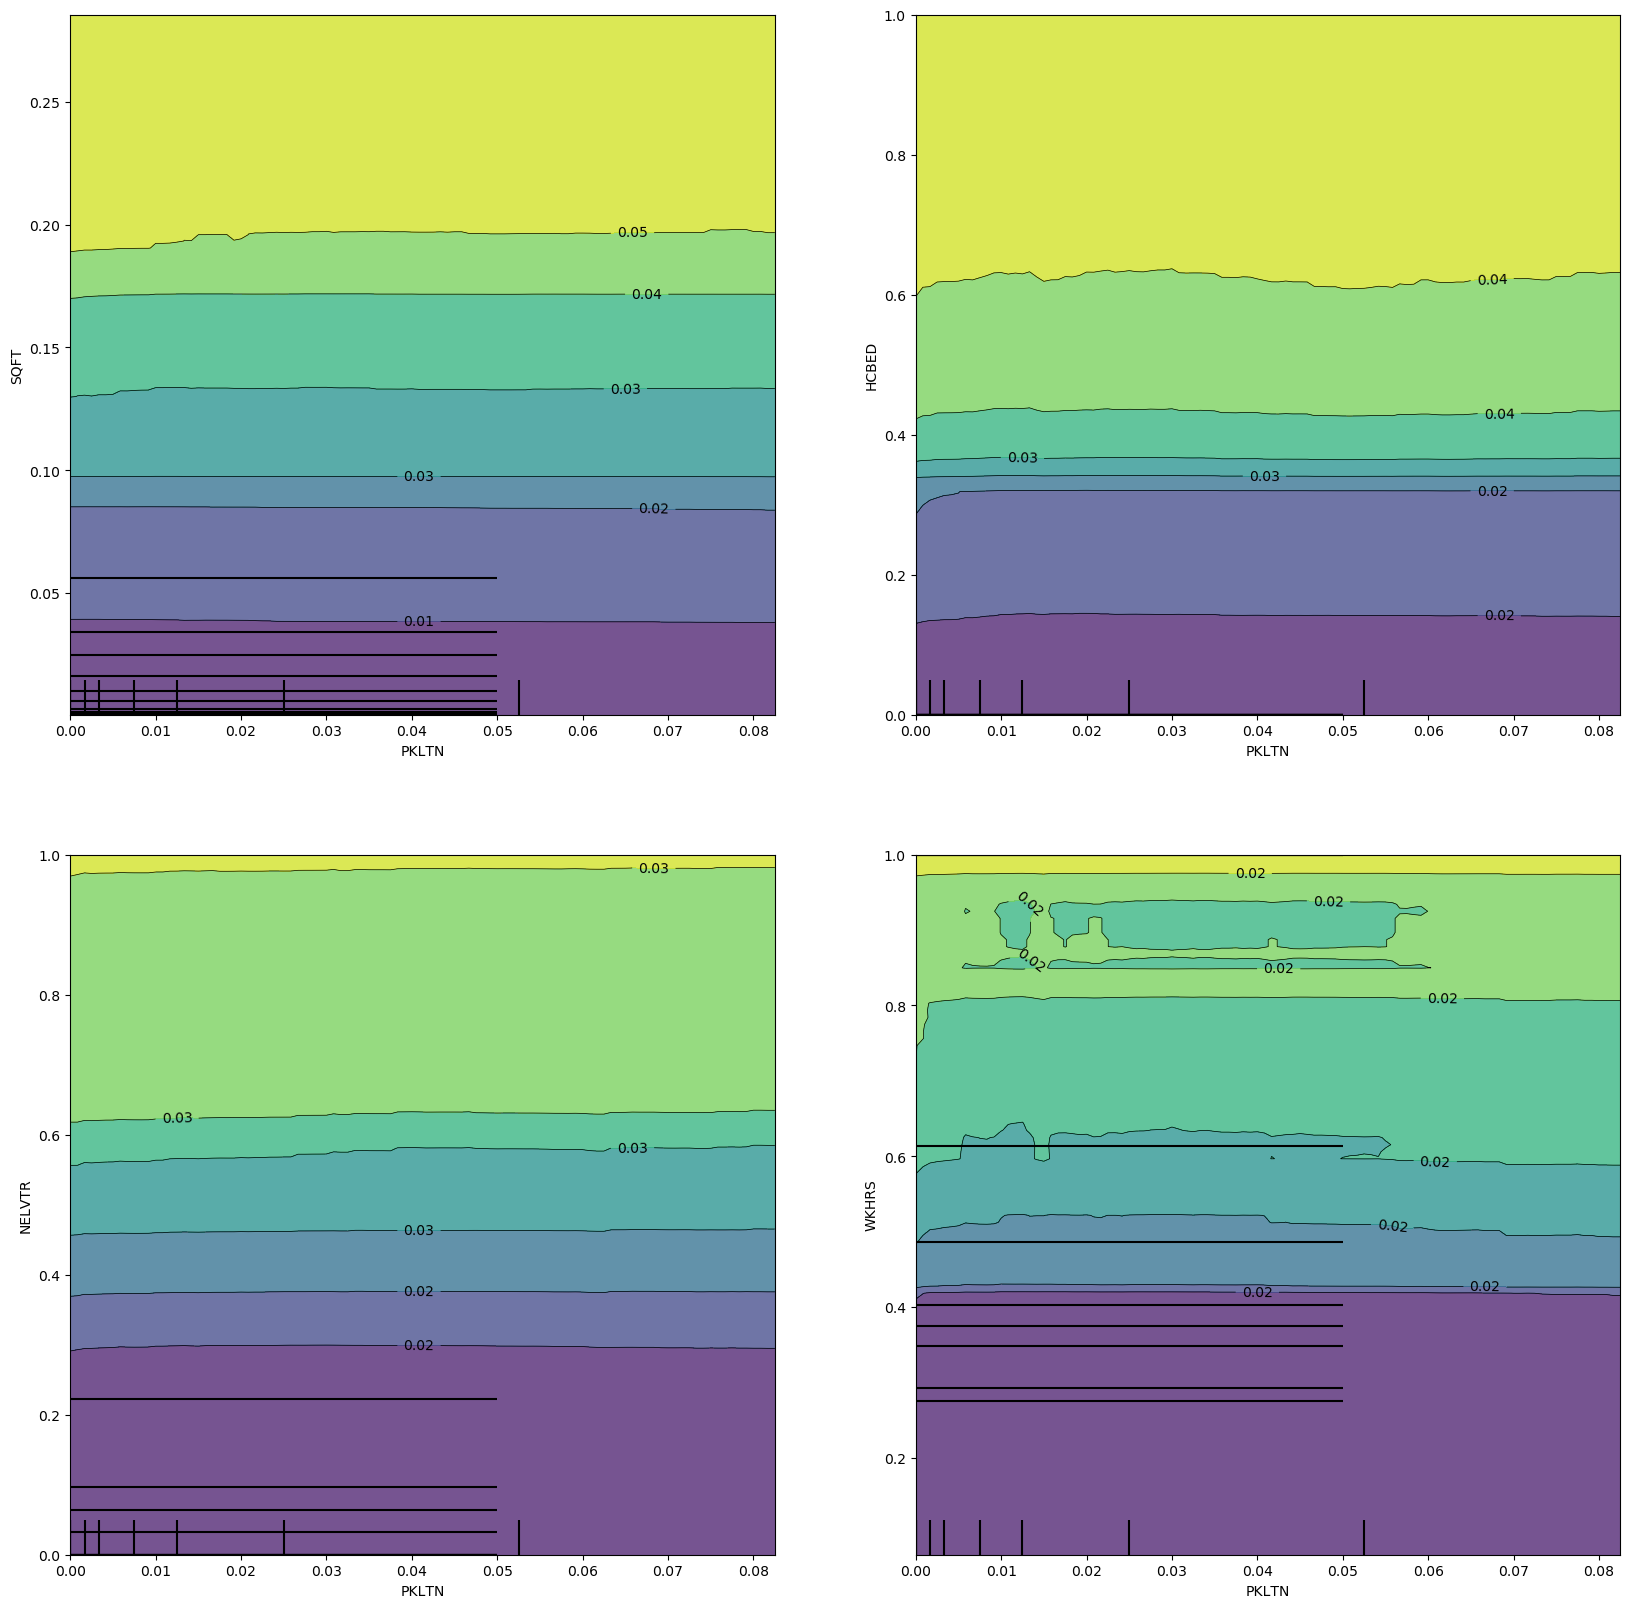

In [12]:
fix, axes = plt.subplots(2, 2, figsize=(20,20))
axes = axes.ravel()


for i, feature in enumerate(['SQFT', 'HCBED', 'NELVTR', 'WKHRS']):
    
    index = [(X_automatic.columns.tolist().index('PKLTN'), X_automatic.columns.tolist().index(feature))]
    pd_plot = PartialDependenceDisplay.from_estimator(random_forest_regressor_automatic, X_automatic, features = index, feature_names= X_automatic.columns, ax=axes[i])
    pd_plot.figure_.set_size_inches(20, 20)

plt.savefig('../images/partialdependence_automaticfeatures_pkltn.png', dpi=300)

# **Local Interpretation**

## **SHAP**

In [13]:
shap_explainer = shap.TreeExplainer(random_forest_regressor_automatic)
test_shap_vals = shap_explainer.shap_values(X_automatic)

In [14]:
shap.initjs()

In [15]:
obs = 0
shap.force_plot(shap_explainer.expected_value, test_shap_vals[obs, :], X_automatic.iloc[obs,:], show=False, matplotlib=True)
plt.savefig('../images/shap_forceplot_automaticfeatures_observation1.png', dpi=300)

In [16]:
#shap.force_plot(shap_explainer.expected_value, test_shap_vals, X_automatic)

In [17]:
fig = plt.figure(figsize=(10,15))
shap.summary_plot(test_shap_vals, X_automatic, plot_size=None, alpha = 0.5, show=False)
plt.savefig('../images/shap_summaryplot_automaticfeatures.png', dpi=300)

In [18]:
for feat in features:
    shap.dependence_plot(feat, test_shap_vals, X_automatic, dot_size=50, alpha = 0.5, show=False)
    plt.savefig(f'../images/shap_dependence_plot_{feat}.png', dpi=300)

## **LIME**

In [19]:
explainer = lime.lime_tabular.LimeTabularExplainer(np.array(X_automatic),  
                                                   feature_names=X_automatic.columns, 
                                                   verbose=True, mode='regression')

In [20]:
i = 0
exp = explainer.explain_instance(np.array(X_automatic)[i], random_forest_regressor_automatic.predict, num_features=len(X_automatic.columns))
#exp.show_in_notebook(show_table=True)
exp.save_to_file('../images/lime_explainer.html')

Intercept 0.04710078820358704
Prediction_local [0.02122898]
Right: 0.022871868090861787
